# Uczenie maszynowe a tradycyjne programowanie

![Programowanie a uczenie maszynowe](../obrazki/2.3_programowanie_vs_ml.png)

**Plan notatnika:**
1. Porównanie ML z tradycyjnym programowaniem
2. Przykład praktyczny: jabłko czy pomarańcza?
3. Wizualne porównanie obu podejść

## 1. Porównanie ML z tradycyjnym programowaniem

| Aspekt | Tradycyjne programowanie | Uczenie maszynowe |
| :--- | :--- | :--- |
| **Podejście** | Programista definiuje **reguły**, które przetwarzają dane na wyniki | System uczy się **reguł** na podstawie danych i pożądanych wyników |
| **Schemat** | Dane + Reguły (algorytm) = Wyniki | Dane + Wyniki (etykiety) = Reguły (model); potem Dane + Model = Wyniki |
| **Rola programisty** | Określa każdy krok algorytmu | Przygotowuje dane, wybiera i konfiguruje model, ale nie pisze reguł decyzyjnych |
| **Adaptacja** | Ograniczona do scenariuszy przewidzianych przez programistę | Może adaptować się do nowych, niewidzianych danych |
| **Złożoność** | Trudności przy bardzo złożonych problemach z wieloma zmiennymi | Lepiej radzi sobie ze złożonymi wzorcami i zależnościami nieliniowymi |
| **Przykłady zadań** | Sortowanie listy, obliczanie podatku według jasnych reguł | Rozpoznawanie obrazów, prognozowanie cen, wykrywanie anomalii |
| **Rozwiązywanie problemów** | Dekompozycja na małe, dokładnie zdefiniowane kroki | Znalezienie odpowiednich danych i pozwolenie modelowi na odkrycie wzorców |
| **Przewidywalność** | Deterministyczne: te same dane wejściowe dają ten sam wynik | Wynik zależy od danych uczących i bywa losowy (np. losowa inicjalizacja) |
| **Interpretacja** | Łatwa do zrozumienia i wytłumaczenia (white-box) | Często trudna, szczególnie dla złożonych modeli (black-box) |
| **Wymagania sprzętowe** | Zazwyczaj małe | Często duże, szczególnie w fazie treningu |

Różnica jest widoczna także w **zarządzaniu projektami**: wycena zadań i oszacowanie wyników w projektach ML jest trudniejsze niż w klasycznych projektach IT.

**Wnioski:**
- **Podejście tradycyjne** wymaga od programisty dogłębnego zrozumienia problemu i ręcznego zdefiniowania reguł. Jest sztywne i trudne w utrzymaniu.
- **Podejście ML** jest bardziej elastyczne: model sam „odkrywa” reguły na podstawie przykładów. Naszym zadaniem jest dostarczyć dobre dane i wybrać odpowiedni model. To inny sposób myślenia o rozwiązywaniu problemów.

## 2. Przykład praktyczny: jabłko czy pomarańcza?

**Problem:** chcemy napisać program, który rozpoznaje, czy owoc to **jabłko** czy **pomarańcza**, na podstawie dwóch cech:
- **waga** (w gramach),
- **tekstura** (0 = gładka, 1 = chropowata).

Mamy zważone i opisane owoce. Część (zbiór **treningowy**) posłuży do budowy reguł lub do uczenia modelu, a część (zbiór **testowy**) zostawiamy do sprawdzenia, jak program radzi sobie z owocami, których wcześniej nie widział. Dane są wymyślone na potrzeby ćwiczenia.

In [5]:
import numpy as np

# Cechy: [waga w gramach, tekstura (0 = gładka, 1 = chropowata)]
# Etykiety: 0 = jabłko, 1 = pomarańcza
X_train = np.array([[120, 0], [140, 0], [150, 0], [165, 0], [175, 0], [185, 0],
                    [130, 1], [145, 1], [150, 1], [170, 1], [190, 1], [200, 1]])
y_train = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1])

X_test = np.array([[125, 0], [160, 0], [180, 0], [195, 0],
                   [135, 1], [155, 1], [165, 1], [185, 1]])
y_test = np.array([0, 0, 0, 0, 1, 1, 1, 1])

### Podejście 1: tradycyjne programowanie (jawne reguły)

Programista na podstawie własnych obserwacji dochodzi do wniosku: „Pomarańcze są zazwyczaj cięższe i mają chropowatą skórkę”.

1. Jeśli owoc jest ciężki (> 150 g), to pewnie pomarańcza.
2. Jeśli jest lżejszy, ale ma chropowatą skórkę, to też pomarańcza.
3. W pozostałych przypadkach to jabłko.

In [6]:
def klasyfikuj_owoc_tradycyjnie(waga, tekstura):
    """Klasyfikuje owoc na podstawie ręcznie zdefiniowanych reguł (1 = pomarańcza, 0 = jabłko)."""
    if waga > 150 or tekstura > 0.5:
        return 1
    return 0


y_pred_trad = np.array([klasyfikuj_owoc_tradycyjnie(w, t) for w, t in X_test])
print("Prawdziwe:  ", y_test)
print("Reguły ręczne:", y_pred_trad)
print(f"Trafność reguł ręcznych na zbiorze testowym: {(y_pred_trad == y_test).mean():.0%}")

Prawdziwe:   [0 0 0 0 1 1 1 1]
Reguły ręczne: [0 1 1 1 1 1 1 1]
Trafność reguł ręcznych na zbiorze testowym: 62%


Reguły wyglądały rozsądnie, ale **błędnie rozpoznają ciężkie jabłka** – intuicja programisty nie wytrzymała konfrontacji z danymi. Przy większej liczbie cech ręczne poprawianie reguł byłoby jeszcze trudniejsze.

### Podejście 2: uczenie maszynowe (uczenie się reguł z danych)

Zamiast pisać reguły, dostarczamy **przykłady** (zbiór treningowy) i pozwalamy modelowi **samemu** znaleźć wzorce. Użyjemy drzewa decyzyjnego (omówimy je szczegółowo w rozdziale 4.1).

1. Wybierz model.
2. „Nakarm” go danymi treningowymi (`fit`).
3. Model sam tworzy wewnętrzne reguły.
4. Użyj modelu do predykcji (`predict`) i sprawdź wynik na zbiorze testowym.

In [7]:
from sklearn.tree import DecisionTreeClassifier, export_text

model_ml = DecisionTreeClassifier(random_state=42)
model_ml.fit(X_train, y_train)

y_pred_ml = model_ml.predict(X_test)
print("Prawdziwe:  ", y_test)
print("Model ML:   ", y_pred_ml)
print(f"Trafność modelu ML na zbiorze testowym: {(y_pred_ml == y_test).mean():.0%}")

# Reguły, które model stworzył sam
print()
print(export_text(model_ml, feature_names=['waga', 'tekstura']))

Prawdziwe:   [0 0 0 0 1 1 1 1]
Model ML:    [0 0 0 0 1 1 1 1]
Trafność modelu ML na zbiorze testowym: 100%

|--- tekstura <= 0.50
|   |--- class: 0
|--- tekstura >  0.50
|   |--- class: 1



Model sam odkrył, że o gatunku decyduje **tekstura**, a waga nie pomaga (jabłka i pomarańcze są podobnej wagi).

**Uwaga:** tu uczenie maszynowe wygrało, bo dane zawierały potrzebną informację. Przy złych lub niereprezentatywnych danych model też się pomyli – dlatego zawsze sprawdzamy go na zbiorze testowym.

## 3. Wizualne porównanie obu podejść

Wykres pokazuje, jak oba podejścia „dzielą” świat na jabłka i pomarańcze. Wypełnione znaczniki to dane treningowe, a znaczniki z czarną obwódką – testowe.

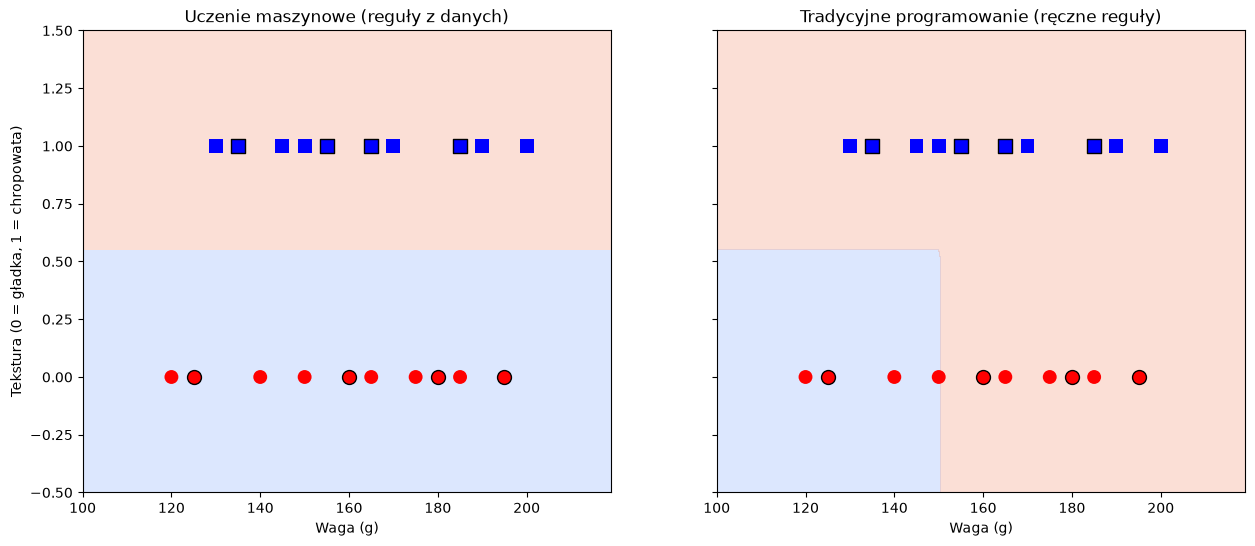

In [8]:
import matplotlib.pyplot as plt

# Siatka punktów, dla których rysujemy decyzję
xx, yy = np.meshgrid(np.arange(100, 220, 1), np.arange(-0.5, 1.6, 0.1))
punkty = np.c_[xx.ravel(), yy.ravel()]

Z_ml = model_ml.predict(punkty).reshape(xx.shape)
Z_trad = np.array([klasyfikuj_owoc_tradycyjnie(w, t) for w, t in punkty]).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for ax, Z, tytul in zip(axes, [Z_ml, Z_trad],
                        ['Uczenie maszynowe (reguły z danych)', 'Tradycyjne programowanie (ręczne reguły)']):
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], alpha=0.3, cmap=plt.cm.coolwarm)
    for X, y, krawedz in [(X_train, y_train, 'none'), (X_test, y_test, 'black')]:
        ax.scatter(X[y == 0, 0], X[y == 0, 1], marker='o', color='red', edgecolors=krawedz, s=100)
        ax.scatter(X[y == 1, 0], X[y == 1, 1], marker='s', color='blue', edgecolors=krawedz, s=100)
    ax.set_title(tytul)
    ax.set_xlabel('Waga (g)')

axes[0].set_ylabel('Tekstura (0 = gładka, 1 = chropowata)')
plt.show()

Czerwone kółka to jabłka, niebieskie kwadraty – pomarańcze. Na wykresie po prawej widać ciężkie jabłka (czerwone kółka na prawo od 150 g), które reguły ręczne zaliczają do pomarańczy. Podział wykonany przez model biegnie poziomo – decyduje tylko tekstura.